Dans ce notebook on implémente et teste la méthode proposée dans [Efficient training of physics-informed neural networks via importance sampling](https://arxiv.org/abs/2104.12325) avec la condition initial et condition au bord incluse dans la loss

## Import

In [18]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize
import scipy.stats as stats
from mpl_toolkits.mplot3d import Axes3D

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

## Paramètres

In [19]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)
viscosity = tf.constant(5e-4, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

## Generer les données

In [20]:
def gen_train_data(N_0, N_b, N_r = 10_000, gaussian = False, sigma = 0.5):

    # Set random seed for reproducible results
    tf.random.set_seed(0)
    
    # Draw uniform sample points for initial boundary data
    t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
    x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
    X_0 = tf.concat([t_0, x_0], axis=1)

    # Evaluate intitial condition at x_0
    u_0 = fun_u_0(x_0)

    # Boundary data
    t_b = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
    x_b = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)
    X_b = tf.concat([t_b, x_b], axis=1)

    # Evaluate boundary condition at (t_b,x_b)
    u_b = fun_u_b(t_b, x_b)

    # sample collocation points
    t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_r = tf.expand_dims(tf.cast(dist.rvs(N_r), dtype=DTYPE), -1)
    else:
        x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
        
    X_r = tf.concat([t_r, x_r], axis=1)
    
    # Collect boundary and inital data in lists
    X_data = [X_0, X_b]
    u_data = [u_0, u_b]

    return X_r, X_data, u_data


def plot_train_data(X_r, X_data, u_data):

    X_0 = X_data[0]
    t_0 = X_0[:,0]
    x_0 = X_0[:,1]

    X_b = X_data[1]
    t_b = X_b[:,0]
    x_b = X_b[:,1]

    t_r = X_r[:,0]
    x_r = X_r[:,1]

    u_0 = u_data[0]
    u_b = u_data[1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_0, x_0, c=u_0[:,0], marker='X', vmin=-1, vmax=1)
    plt.colorbar()
    plt.scatter(t_b, x_b, c=u_b[:,0], marker='X', vmin=-1, vmax=1)
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1)
    plt.xlabel('$t$')
    plt.ylabel('$x$')

    plt.title('Positions of collocation points and boundary data');

In [21]:
def plot_sampled_batch(X):
    
    fig, axs = plt.subplots(len(X), figsize=(10,8*len(X)))
    
    for i,(epoch,batch) in enumerate(X):
        
        
        t = batch[:,0]
        x = batch[:,1]

        axs[i].scatter(t, x, c='r', marker='.', alpha=0.1)
        axs[i].set_xlabel('$t$')
        axs[i].set_ylabel('$x$')
        axs[i].set_title('Epoch {}'.format(epoch))

## Residu/entropie

In [22]:
def get_residual(model, X_r):
    """fonction qui calcule le résidu"""
    
    # Split t and x to compute partial derivatives
    t, x = X_r[:, 0:1], X_r[:,1:2]
        
    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t and x during this GradientTape
        tape.watch(t)
        tape.watch(x)

        # Compute current values u(t,x) and u(t,x)^2
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)

        u_x = tape.gradient(u, x)

    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t + u2_x/2. - viscosity * u_xx

def get_entropy(model, X_r):
    """fonction qui calcule l'entropie """
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)

        # Determine residual 
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)
        u3 = u*u2

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u2_x = tape.gradient(u2, x)
            
    eta_t = tape.gradient(u2, t)
    q_x = tape.gradient(u3, x)
    eta_xx = tape.gradient(u2_x, x)

    del tape

    return eta_t/2 +  q_x/3 - viscosity * eta_xx

## Architecture PINN

In [23]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y

## Entrainement classique

In [24]:
class PINNSolver():
    def __init__(self, model, batch_size = 1_000):
        self.model = model

        # Initialize history of losses and global iteration counter
        self.hist = []
        self.epoch = 0
        self.batch_size = batch_size
        self.batch_history = []
        
    def get_r(self, x):
        
        t = x[:,0:1]
        x = x[:,1:2]
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(t)
            tape.watch(x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([t[:,0], x[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, x)
            
        u_t = tape.gradient(u, t)
        u_xx = tape.gradient(u_x, x)
        u2_x = tape.gradient(u2, x)

        del tape
        
        return u_t + u2_x/2. - viscosity * u_xx
    
    def loss_fn(self, x, X, u):
        
        # Compute phi_r
        r = self.get_r(x)
        phi_r = tf.reduce_mean(tf.square(r))

        # Initialize loss
        loss = phi_r
        
        # Add phi_0 and phi_b to the loss
        for i in range(len(X)):
            u_pred = self.model(X[i])
            loss += tf.reduce_mean(tf.square(u[i] - u_pred))
        
        return loss
    
    def get_grad(self, x, X, u):
        
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(x, X, u)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def solve_with_TFoptimizer(self, optimizer, X_train, X_data, u_data):
        """This method performs a gradient descent type optimization."""
        
        @tf.function
        def train_step(x, X, u):
            loss, grad_theta = self.get_grad(x, X, u)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss

        num_epochs = 3_000
        for epoch in range(num_epochs):
            
          for step in range(10):

            indices = np.random.choice(len(X_r), size=self.batch_size, replace=False)
            batch = tf.gather(X_r, indices)

            loss = train_step(batch, X_data, u_data)
            
            
          self.current_loss = loss.numpy()
          self.callback()
          if epoch % 100 == 0:
            self.batch_history.append( (epoch, batch) )
                          
    def callback(self, xr=None):
        
        if self.epoch % 100 == 0:
            print('Epoch {:04d}: loss = {:10.8e}'.format(self.epoch,self.current_loss))
        self.hist.append(self.current_loss)
        self.epoch+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

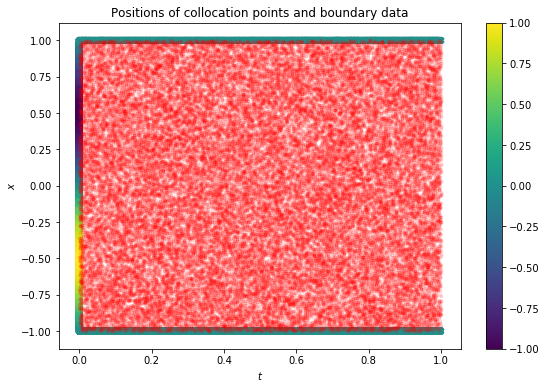

In [25]:
X_r, X_data, u_data = gen_train_data(10_000,10_000,50_000)
plot_train_data(X_r, X_data, u_data)

In [26]:
model_v1 = PhysicsInformedNN(lb, ub, num_hidden_layers=6, num_neurons_per_layer=30, activation='tanh')
# Initilize PINN solver
solver_v1 = PINNSolver(model_v1, batch_size = 10_000)

# training
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver_v1.solve_with_TFoptimizer(optim, X_r, X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 0000: loss = 4.07231539e-01
Epoch 0100: loss = 8.01237077e-02
Epoch 0200: loss = 7.81218708e-02
Epoch 0300: loss = 7.75478482e-02
Epoch 0400: loss = 7.92008191e-02
Epoch 0500: loss = 6.97216615e-02
Epoch 0600: loss = 7.13291392e-02
Epoch 0700: loss = 6.37926310e-02
Epoch 0800: loss = 6.30758479e-02
Epoch 0900: loss = 5.69263659e-02
Epoch 1000: loss = 5.38550094e-02
Epoch 1100: loss = 4.63026874e-02
Epoch 1200: loss = 4.09048609e-02
Epoch 1300: loss = 3.64054404e-02
Epoch 1400: loss = 3.34122777e-02
Epoch 1500: loss = 3.03868968e-02
Epoch 1600: loss = 2.84084044e-02
Epoch 1700: loss = 2.63804197e-02
Epoch 1800: loss = 2.57135946e-02
Epoch 1900: loss = 2.36966237e-02
Epoch 2000: loss = 2.31668185e-02
Epoch 2100: loss = 2.20014993e-02
Epoch 2200: loss = 2.32014824e-02
Epoch 2300: loss = 2.20135897e-02
Epoch 2400: loss = 2.24189870e-02
Epoch 2500: loss = 2.22780909e-02
Epoch 2600: loss = 2.11165901e-02
Epoch 2700: loss = 2.14558076e-02
Epoch 2800: loss = 2.01924108e-02
Epoch 2900: lo

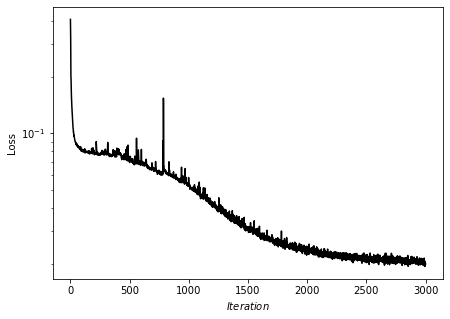

In [27]:
solver_v1.plot_loss_history();



In [28]:
plot_sampled_batch(solver_v1.batch_history);

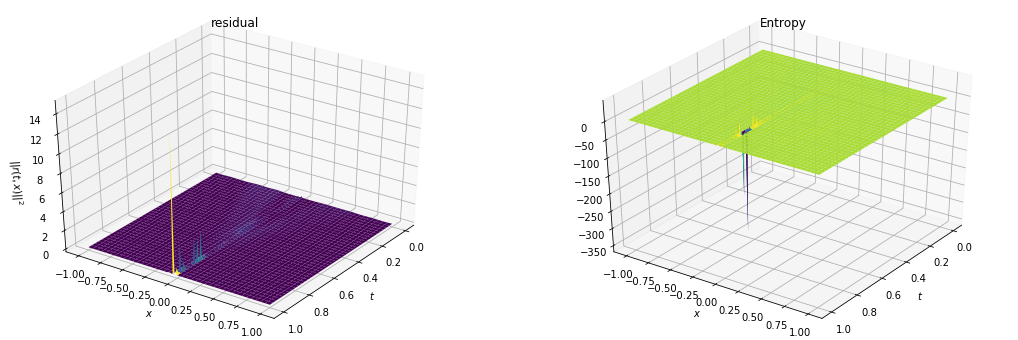

In [29]:
# Set up meshgrid for plotting
N_test = 200
tspace = np.linspace(lb[0], ub[0], N_test + 1)
xspace = np.linspace(lb[1], ub[1], N_test + 1)
T, X = np.meshgrid(tspace, xspace)
X_test = np.vstack([T.flatten(),X.flatten()]).T


# compute and reshape residual for plotting
Res = get_residual(model_v1, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model_v1,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, rcount=50, ccount=50, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');

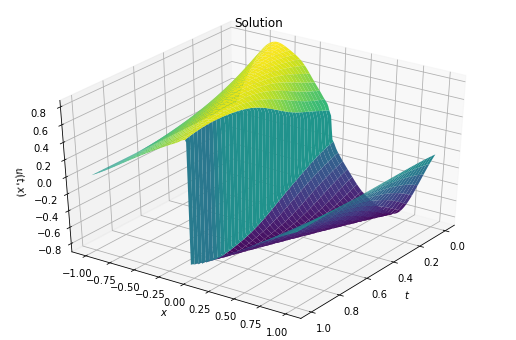

In [30]:
U = model_v1.call(tf.cast(X_test,DTYPE)).numpy().reshape(N_test+1,N_test+1)
# Surface plot of u
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, U, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$u(t,x)$')
ax.set_title('Solution');

## En utilisant les seeds

In [31]:
from scipy.spatial import KDTree

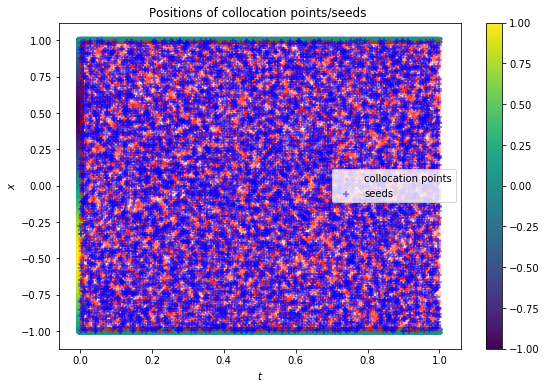

In [36]:
def gen_train_data_v2(N_0, N_b, N_r, N_s, gaussian = False, sigma = 0.5):

    # Set random seed for reproducible results
    tf.random.set_seed(0)
    
    # Draw uniform sample points for initial boundary data
    t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
    x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
    X_0 = tf.concat([t_0, x_0], axis=1)

    # Evaluate intitial condition at x_0
    u_0 = fun_u_0(x_0)

    # Boundary data
    t_b = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
    x_b = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)
    X_b = tf.concat([t_b, x_b], axis=1)

    # Evaluate boundary condition at (t_b,x_b)
    u_b = fun_u_b(t_b, x_b)

    # sample collocation points
    t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_r = tf.expand_dims(tf.cast(dist.rvs(N_r), dtype=DTYPE), -1)
    else:
        x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
        
    X_r = tf.concat([t_r, x_r], axis=1)
    
    # sample seeds
    t_s = tf.random.uniform((N_s,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_s = tf.expand_dims(tf.cast(dist.rvs(N_s), dtype=DTYPE), -1)
    else:
        x_s = tf.random.uniform((N_s,1), lb[1], ub[1], dtype=DTYPE)
        
    X_s = tf.concat([t_s, x_s], axis=1)
    
    # Collect boundary and inital data in lists
    X_data = [X_0, X_b]
    u_data = [u_0, u_b]

    return X_r, X_s, X_data, u_data

def plot_train_data_v2(X_r, X_s, X_data, u_data):
    
    X_0 = X_data[0]
    t_0 = X_0[:,0]
    x_0 = X_0[:,1]

    X_b = X_data[1]
    t_b = X_b[:,0]
    x_b = X_b[:,1]
    
    t_r = X_r[:,0]
    x_r = X_r[:,1]
    
    t_s = X_s[:,0]
    x_s = X_s[:,1]

    u_0 = u_data[0]
    u_b = u_data[1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_0, x_0, c=u_0[:,0], marker='X', vmin=-1, vmax=1)
    plt.colorbar()
    plt.scatter(t_b, x_b, c=u_b[:,0], marker='X', vmin=-1, vmax=1)
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1, label='collocation points')
    plt.scatter(t_s, x_s, c='b', marker='+', alpha=0.5, label='seeds')
    plt.xlabel('$t$')
    plt.ylabel('$x$')
    plt.legend()

    plt.title('Positions of collocation points/seeds ');

X_r, X_s, X_data, u_data = gen_train_data_v2(10_000,10_000,50_000, 10_000)
plot_train_data_v2(X_r, X_s, X_data, u_data)

In [37]:
class PINNSolver_v2():
    def __init__(self, model, batch_size = 1_000):
        self.model = model

        # Initialize history of losses and global iteration counter
        self.hist = []
        self.epoch = 0
        self.batch_size = batch_size
        self.batch_history = []
        
    def get_r(self, x):
        
        t = x[:,0:1]
        x = x[:,1:2]
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(t)
            tape.watch(x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([t[:,0], x[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, x)
            
        u_t = tape.gradient(u, t)
        u_xx = tape.gradient(u_x, x)
        u2_x = tape.gradient(u2, x)

        del tape
        
        return u_t + u2_x/2. - viscosity * u_xx
    
    def loss_fn(self, x, X, u):
        
        # Compute phi_r
        r = self.get_r(x)
        phi_r = tf.reduce_mean(tf.square(r))

        # Initialize loss
        loss = phi_r
        
        # Add phi_0 and phi_b to the loss
        for i in range(len(X)):
            u_pred = self.model(X[i])
            loss += tf.reduce_mean(tf.square(u[i] - u_pred))
        
        return loss
    
    def get_grad(self, x, X, u):
        
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(x, X, u)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def solve_with_TFoptimizer(self, optimizer, X_r, X_seeds, X_data, u_data):
        """This method performs a gradient descent type optimization."""

        # initilisation du KD_tree avec les seeds
        tree = KDTree(X_seeds)

        # localisation dans le KD_tree
        _, ii = tree.query(X_r, k=1)
        #X_rho = tf.gather(X_seeds, ii)

        @tf.function
        def train_step(x, X, u):
            loss, grad_theta = self.get_grad(x, X, u)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
                    
        num_epochs = 3_000
        for epoch in range(num_epochs):

          # calcul de q_i
          J_seeds = self.get_r(X_seeds)
          J_rho = tf.gather(J_seeds, ii)
          sum_J_rho = tf.reduce_sum(J_rho**2)
          q = J_rho**2 / sum_J_rho
          q = q.numpy().flatten()
        
          for step in range(10):

              # tire les points 
              indices = np.random.choice(len(X_r), size=self.batch_size, replace=False, p=q)
              batch = tf.gather(X_r, indices)

              # descente de gradient
              loss = train_step(batch, X_data, u_data)

          self.current_loss = loss.numpy()
          self.callback()
          if epoch % 100 == 0:
            self.batch_history.append( (epoch, batch) )
                          
    def callback(self, xr=None):
        
        if self.epoch % 100 == 0:
            print('Epoch {:04d}: loss = {:10.8e}'.format(self.epoch,self.current_loss))
        self.hist.append(self.current_loss)
        self.epoch+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

In [38]:
model_v2 = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')
# Initilize PINN solver
solver_v2 = PINNSolver_v2(model_v2, batch_size = 10_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver_v2.solve_with_TFoptimizer(optim, X_r, X_s, X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 0000: loss = 4.19330269e-01
Epoch 0100: loss = 1.76227599e-01
Epoch 0200: loss = 1.27961352e-01
Epoch 0300: loss = 1.15940601e-01
Epoch 0400: loss = 1.09619945e-01
Epoch 0500: loss = 1.07983574e-01
Epoch 0600: loss = 1.06191672e-01
Epoch 0700: loss = 1.06234729e-01
Epoch 0800: loss = 1.05209678e-01
Epoch 0900: loss = 1.03817217e-01
Epoch 1000: loss = 1.02278888e-01
Epoch 1100: loss = 1.02078862e-01
Epoch 1200: loss = 1.01308599e-01

Training time: 234.76154255867004 seconds


In [ ]:
plot_sampled_batch(solver_v2.batch_history);

In [ ]:
solver_v2.plot_loss_history()

In [ ]:
# Set up meshgrid for plotting
N_test = 200
tspace = np.linspace(lb[0], ub[0], N_test + 1)
xspace = np.linspace(lb[1], ub[1], N_test + 1)
T, X = np.meshgrid(tspace, xspace)
X_test = np.vstack([T.flatten(),X.flatten()]).T


# compute and reshape residual for plotting
Res = get_residual(model_v2, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model_v2,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_title('residual');
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, rcount=50, ccount=50, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');

In [ ]:
U = model_v2.call(tf.cast(X_test,DTYPE)).numpy().reshape(N_test+1,N_test+1)
# Surface plot of u
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, U, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$u(t,x)$')
ax.set_title('Solution');